# Evaluación final: Full vs Random-70 vs Agent

Tesis: Framework de selección inteligente de datos para el entrenamiento eficiente de modelos de lenguaje mediante aprendizaje por refuerzo y estimación del consumo energético. (Fase 3)

Este notebook recibe la política PPO congelada de la fase 2 (entrenamiento PPO) y realiza la evaluación final sobre el conjunto de prueba oficial de IMDb, AG News y TREC.

Antes de la evaluación se aplica una etapa de descontaminación exacta por texto: se preserva íntegramente el conjunto de prueba y se eliminan del conjunto de entrenamiento y del de validación las coincidencias textuales exactas detectadas mediante SHA-256. Esta etapa evita evaluar sobre textos idénticos a los usados para ajustar el modelo objetivo.


## 1. Configuración y reproducibilidad

Se carga el modelo final de la fase 2 (entrenamiento PPO) y se usa de forma determinista (`deterministic=True`). Las reejecuciones reutilizan los resultados guardados y no vuelven a medir energía cuando el `result.json` ya existe.


In [ ]:
!pip -q install \
    "stable-baselines3==2.9.0" \
    "gymnasium==1.3.0" \
    "codecarbon==3.3.1" \
    "transformers==5.16.1" \
    "datasets==4.8.5" \
    "pandas==2.2.3" \
    "numpy==2.1.3" \
    "scikit-learn==1.9.1" \
    pyarrow

In [ ]:
from __future__ import annotations

from datetime import datetime
import gc
import hashlib
import importlib.metadata as md
import json
import math
import os
import pickle
import random
import time
import warnings
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, f1_score
from stable_baselines3 import PPO
from codecarbon import EmissionsTracker
from transformers import AutoModelForSequenceClassification, AutoTokenizer

warnings.filterwarnings("ignore")

EXPERIMENT_NAME = "final_evaluation_v2"
N_TRAIN = 800
N_VAL = 300
MAX_TOKEN_CAP = 256
MIN_TOKEN_CAP = 8
BATCH_SIZE = 16
TRAIN_EPOCHS = 1
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.0
CODECARBON_MEASURE_POWER_SECS = 1
EVAL_SEEDS = [101, 202, 303, 404, 505]
DATASETS = ["imdb", "ag_news", "trec"]
CONDITIONS = ["Full", "Random-70", "Agent"]
DATASET_INFO = {"imdb": {"num_classes": 2}, "ag_news": {"num_classes": 4}, "trec": {"num_classes": 6}}

DRIVE_ROOT = Path("/content/drive/MyDrive/idsf-eft/framework")
ARTIFACT_ROOT = DRIVE_ROOT / "artifacts"
PPO_RUN_ROOT = DRIVE_ROOT / "ppo_training" / "ppo_shared_final_v2"
MODEL_PATH = PPO_RUN_ROOT / "models" / "ppo_shared_final.zip"
EVAL_ROOT = DRIVE_ROOT / "final_evaluation_v2"
RESULT_ROOT = EVAL_ROOT / "results"
CODECARBON_ROOT = EVAL_ROOT / "codecarbon"
SELECTION_ROOT = EVAL_ROOT / "selections"

print("Evaluation root:", EVAL_ROOT)
print("Frozen PPO:", MODEL_PATH)
print("Device target model:", "cuda" if torch.cuda.is_available() else "cpu")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Evaluation root: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2
Frozen PPO: /content/drive/MyDrive/idsf-eft/framework/ppo_training/ppo_shared_final_v2/models/ppo_shared_final.zip
Device target model: cuda


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
for p in [EVAL_ROOT, RESULT_ROOT, CODECARBON_ROOT, SELECTION_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print("Drive montado y carpetas de evaluación listas.")

Drive montado y carpetas de evaluación listas.


## 2. Control del entorno

Se comprueban las mismas versiones de software que se usaron en la fase 2 para congelar la politica PPO. La GPU puede ser diferente entre sesiones de Colab y se registra como parte del experimento.

In [ ]:
EXPECTED_VERSIONS = {
    "stable-baselines3": "2.9.0",
    "gymnasium": "1.3.0",
    "codecarbon": "3.3.1",
    "transformers": "5.16.1",
    "datasets": "4.8.5",
    "pandas": "2.2.3",
    "numpy": "2.1.3",
    "scikit-learn": "1.9.1",
}
VERSIONS = {}
for package in list(EXPECTED_VERSIONS) + ["torch", "pyarrow"]:
    try:
        VERSIONS[package] = md.version(package)
    except md.PackageNotFoundError:
        VERSIONS[package] = "NO INSTALADO"

version_df = pd.DataFrame([{"package": k, "version": v} for k, v in VERSIONS.items()])
display(version_df)

for package, expected in EXPECTED_VERSIONS.items():
    actual = VERSIONS.get(package)
    if actual != expected:
        raise RuntimeError(f"Versión no reproducible para {package}: {actual}; se esperaba {expected}.")
if not VERSIONS["torch"].startswith("2.11.0"):
    raise RuntimeError(f"PyTorch actual={VERSIONS['torch']}. Se requiere PyTorch 2.11.0.x.")
if VERSIONS.get("pyarrow") == "NO INSTALADO":
    raise RuntimeError("pyarrow es necesario para leer los artefactos Parquet de Notebook 1.")

GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print("GPU:", GPU_NAME)

,package,version
0,stable-baselines3,2.9.0
1,gymnasium,1.3.0
2,codecarbon,3.3.1
3,transformers,5.16.1
4,datasets,4.8.5
5,pandas,2.2.3
6,numpy,2.1.3
7,scikit-learn,1.9.1
8,torch,2.11.0+cu130
9,pyarrow,23.0.1


GPU: Tesla T4


## 3. Cargar la política entrenada en la fase 2

In [ ]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"No existe la política congelada: {MODEL_PATH}")

final_manifest_path = PPO_RUN_ROOT / "experiment_manifest.json"
repro_manifest_path = PPO_RUN_ROOT / "reproducibility_manifest.json"
config_path = PPO_RUN_ROOT / "ppo_config.json"
history_path = PPO_RUN_ROOT / "ppo_final_history.csv"

for p in [final_manifest_path, repro_manifest_path, config_path, history_path]:
    if not p.exists():
        raise FileNotFoundError(f"Falta artefacto de Notebook 2: {p}")

with open(final_manifest_path, "r", encoding="utf-8") as f:
    ppo_manifest = json.load(f)
with open(repro_manifest_path, "r", encoding="utf-8") as f:
    ppo_repro = json.load(f)
with open(config_path, "r", encoding="utf-8") as f:
    ppo_config = json.load(f)

assert ppo_manifest.get("status") == "completed"
assert int(ppo_manifest.get("completed_episodes", -1)) == 600
assert ppo_repro.get("completed_episodes") == 600
model_hash = sha256_file(MODEL_PATH)
assert model_hash == ppo_repro.get("model_sha256"), "El hash del modelo no coincide con Notebook 2."

frozen_history = pd.read_csv(history_path)
assert len(frozen_history) == 600
assert frozen_history["episode_index"].tolist() == list(range(600))

print("Modelo congelado validado.")
print("Modelo SHA-256:", model_hash)
print("Experimento PPO:", ppo_manifest.get("experiment_signature"))

Modelo congelado validado.
Modelo SHA-256: 937eb0a768a23f649e58691ed3ba08dac9785857343546330378b04c0d781c28
Experimento PPO: 0ac47a4596c06aebf5b90c499c6fde6c68caf52da12ab30e3937171c4f7a8d21


## 4. Cargar datasets y características

Se cargan los 800 ejemplos de entrenamiento, los 300 de validación y el split de prueba oficial. El agente obtiene su acción únicamente del descriptor 18D y usa las características por ejemplo calculadas en el pipeline.


In [ ]:
required = [
    ARTIFACT_ROOT / "pipeline_metadata.json",
    ARTIFACT_ROOT / "descriptors" / "dataset_descriptors_18d.csv",
    ARTIFACT_ROOT / "features" / "selection_normalizers.json",
]
for d in DATASETS:
    required += [
        ARTIFACT_ROOT / "datasets" / f"{d}_train.parquet",
        ARTIFACT_ROOT / "datasets" / f"{d}_validation.parquet",
        ARTIFACT_ROOT / "datasets" / f"{d}_test.parquet",
        ARTIFACT_ROOT / "features" / f"{d}_train800_features.parquet",
    ]
missing = [str(p) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Faltan artefactos:\n" + "\n".join(missing))

descriptor_df = pd.read_csv(ARTIFACT_ROOT / "descriptors" / "dataset_descriptors_18d.csv", index_col=0)
feature_tables: Dict[str, pd.DataFrame] = {}
split_tables: Dict[str, Dict[str, pd.DataFrame]] = {}

for d in DATASETS:
    feature_tables[d] = pd.read_parquet(ARTIFACT_ROOT / "features" / f"{d}_train800_features.parquet")
    split_tables[d] = {
        "train": pd.read_parquet(ARTIFACT_ROOT / "datasets" / f"{d}_train.parquet"),
        "validation": pd.read_parquet(ARTIFACT_ROOT / "datasets" / f"{d}_validation.parquet"),
        "test": pd.read_parquet(ARTIFACT_ROOT / "datasets" / f"{d}_test.parquet"),
    }

assert descriptor_df.shape == (3, 18)
assert list(descriptor_df.index) == DATASETS
assert np.isfinite(descriptor_df.to_numpy()).all()
assert ((descriptor_df.to_numpy() >= 0) & (descriptor_df.to_numpy() <= 1)).all()

for d in DATASETS:
    assert len(feature_tables[d]) == N_TRAIN
    assert len(split_tables[d]["train"]) == N_TRAIN
    assert len(split_tables[d]["validation"]) == N_VAL
    assert len(split_tables[d]["test"]) > 0
    assert feature_tables[d]["source_index"].nunique() == N_TRAIN

print("Datasets cargados.")
display(descriptor_df.round(4))

Datasets cargados.


,ppl_mean,ppl_std,ppl_p25,ppl_p75,length_mean,length_std,length_p25,length_p75,div_mean,div_std,div_p25,div_p75,num_classes_norm,class_entropy_norm,p_gt_32,p_gt_64,p_gt_128,p_gt_192
dataset,,,,,,,,,,,,,,,,,,
imdb,0.1815,0.1192,0.0926,0.2546,0.5418,0.2807,0.3205,0.7792,0.0938,0.1413,0.0118,0.1112,0.3333,0.3869,0.9975,0.9725,0.8550,0.5925
ag_news,0.3332,0.2117,0.1719,0.4794,0.0927,0.0303,0.0737,0.1084,0.3551,0.2232,0.1895,0.4634,0.6667,0.7737,0.9275,0.0975,0.0025,0.0000
trec,0.6060,0.2910,0.3914,0.8509,0.0097,0.0093,0.0022,0.0130,0.4956,0.2765,0.2687,0.6995,1.0000,0.9211,0.0012,0.0000,0.0000,0.0000


## Descontaminación
A continuación se ejecuta una etapa de descontaminación exacta por texto. El conjunto de prueba se mantiene intacto, solo se retiran del conjunto de entrenamiento y del de validación los textos que aparecen exactamente en el conjunto de prueba y, después, cualquier coincidencia exacta residual entre entrenamiento y validación. Esta operación queda documentada en `decontamination_report.csv`.

In [ ]:
# --- Descontaminación del Train/Validation ---

def text_hash_series(df: pd.DataFrame) -> set[str]:
    return {hashlib.sha256(str(x).encode("utf-8")).hexdigest() for x in df["text"].astype(str).tolist()}

decontamination_rows = []

for d in DATASETS:
    train_df = split_tables[d]["train"]
    val_df = split_tables[d]["validation"]
    test_df = split_tables[d]["test"]

    row = {
        "dataset": d,
        "train_before": int(len(train_df)),
        "validation_before": int(len(val_df)),
        "test_size": int(len(test_df)),
    }

    # 1. Train vs Test: se protege el Test y se eliminan coincidencias de Train.
    h_train = text_hash_series(train_df)
    h_test = text_hash_series(test_df)
    overlap_train_test = h_train & h_test
    mask_remove = train_df["text"].astype(str).apply(
        lambda x: hashlib.sha256(str(x).encode("utf-8")).hexdigest()
    ).isin(overlap_train_test)
    removed_indices = train_df.loc[mask_remove, "source_index"].astype(int).tolist()

    row["exact_overlap_train_test"] = int(len(overlap_train_test))
    row["train_rows_removed_vs_test"] = int(mask_remove.sum())
    row["train_removed_source_indices_vs_test"] = json.dumps(removed_indices, ensure_ascii=False)

    if mask_remove.any():
        print(f"[{d.upper()}] Filtrando {int(mask_remove.sum())} fila(s) de Train por coincidencia exacta con Test.")
        split_tables[d]["train"] = train_df.loc[~mask_remove].reset_index(drop=True)
        feature_tables[d] = feature_tables[d][~feature_tables[d]["source_index"].isin(removed_indices)].reset_index(drop=True)
        print(f"-> Nuevo tamaño de {d.upper()} Train: {len(split_tables[d]['train'])}")

    # 2. Validation vs Test: se protege el Test y se eliminan coincidencias de Validation.
    val_df = split_tables[d]["validation"]
    h_val = text_hash_series(val_df)
    overlap_val_test = h_val & h_test
    mask_remove_val = val_df["text"].astype(str).apply(
        lambda x: hashlib.sha256(str(x).encode("utf-8")).hexdigest()
    ).isin(overlap_val_test)
    row["exact_overlap_validation_test"] = int(len(overlap_val_test))
    row["validation_rows_removed_vs_test"] = int(mask_remove_val.sum())

    if mask_remove_val.any():
        print(f"[{d.upper()}] Filtrando {int(mask_remove_val.sum())} fila(s) de Validation por coincidencia exacta con Test.")
        split_tables[d]["validation"] = val_df.loc[~mask_remove_val].reset_index(drop=True)
        print(f"-> Nuevo tamaño de {d.upper()} Validation: {len(split_tables[d]['validation'])}")

    # 3. Train vs Validation: se protege Validation y se deja Train/Validation disjuntos.
    train_df = split_tables[d]["train"]
    val_df = split_tables[d]["validation"]
    h_train = text_hash_series(train_df)
    h_val = text_hash_series(val_df)
    overlap_train_val = h_train & h_val
    mask_remove_tv = train_df["text"].astype(str).apply(
        lambda x: hashlib.sha256(str(x).encode("utf-8")).hexdigest()
    ).isin(overlap_train_val)
    removed_indices_tv = train_df.loc[mask_remove_tv, "source_index"].astype(int).tolist()

    row["exact_overlap_train_validation_after_test_filter"] = int(len(overlap_train_val))
    row["train_rows_removed_vs_validation"] = int(mask_remove_tv.sum())
    row["train_removed_source_indices_vs_validation"] = json.dumps(removed_indices_tv, ensure_ascii=False)

    if mask_remove_tv.any():
        print(f"[{d.upper()}] Filtrando {int(mask_remove_tv.sum())} fila(s) de Train por coincidencia exacta con Validation.")
        split_tables[d]["train"] = train_df.loc[~mask_remove_tv].reset_index(drop=True)
        feature_tables[d] = feature_tables[d][~feature_tables[d]["source_index"].isin(removed_indices_tv)].reset_index(drop=True)
        print(f"-> Nuevo tamaño de {d.upper()} Train: {len(split_tables[d]['train'])}")

    row["train_after"] = int(len(split_tables[d]["train"]))
    row["validation_after"] = int(len(split_tables[d]["validation"]))
    row["test_after"] = int(len(split_tables[d]["test"]))
    row["pdu_full_vs_nominal_train"] = float(len(feature_tables[d]) / N_TRAIN)

    # Control final de disjunción textual.
    h_train_final = text_hash_series(split_tables[d]["train"])
    h_val_final = text_hash_series(split_tables[d]["validation"])
    h_test_final = text_hash_series(split_tables[d]["test"])
    assert h_train_final.isdisjoint(h_val_final), f"Solapamiento Train/Validation en {d}"
    assert h_train_final.isdisjoint(h_test_final), f"Solapamiento Train/Test en {d}"
    assert h_val_final.isdisjoint(h_test_final), f"Solapamiento Validation/Test en {d}"

    decontamination_rows.append(row)

# Auditoría del proceso de descontaminación.
decontamination_df = pd.DataFrame(decontamination_rows)
decontamination_df.to_csv(EVAL_ROOT / "decontamination_report.csv", index=False)
display(decontamination_df[[
    "dataset", "train_before", "validation_before", "test_size",
    "exact_overlap_train_test", "train_rows_removed_vs_test",
    "exact_overlap_validation_test", "validation_rows_removed_vs_test",
    "exact_overlap_train_validation_after_test_filter", "train_rows_removed_vs_validation",
    "train_after", "validation_after", "test_after", "pdu_full_vs_nominal_train"]])

print(
    "Descontaminación exacta completada."
)

[IMDB] Filtrando 1 fila(s) de Train por coincidencia exacta con Test.
-> Nuevo tamaño de IMDB Train: 799
[IMDB] Filtrando 3 fila(s) de Validation por coincidencia exacta con Test.
-> Nuevo tamaño de IMDB Validation: 297
[TREC] Filtrando 1 fila(s) de Validation por coincidencia exacta con Test.
-> Nuevo tamaño de TREC Validation: 299
[TREC] Filtrando 2 fila(s) de Train por coincidencia exacta con Validation.
-> Nuevo tamaño de TREC Train: 798


,dataset,train_before,validation_before,test_size,exact_overlap_train_test,train_rows_removed_vs_test,exact_overlap_validation_test,validation_rows_removed_vs_test,exact_overlap_train_validation_after_test_filter,train_rows_removed_vs_validation,train_after,validation_after,test_after,pdu_full_vs_nominal_train
0,imdb,800,300,25000,1,1,3,3,0,0,799,297,25000,0.99875
1,ag_news,800,300,7600,0,0,0,0,0,0,800,300,7600,1.00000
2,trec,800,300,500,0,0,1,1,2,2,798,299,500,0.99750


Descontaminación exacta completada.


## 5. Semillas y entrenamiento del modelo objetivo

La inicialización del clasificador de DistilBERT es una fuente de variación. Por eso cada condición se repite con las mismas cinco semillas. La política PPO se usa congelada con `deterministic=True`.

In [ ]:
def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    if hasattr(torch.backends.cuda, "matmul"):
        torch.backends.cuda.matmul.allow_tf32 = False
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.allow_tf32 = False
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

set_global_seed(42)

In [ ]:
TARGET_MODEL_NAME = ppo_manifest["config"]["target_model"]
target_tokenizer = AutoTokenizer.from_pretrained(TARGET_MODEL_NAME)

class DynamicTextCollator:
    def __init__(self, tokenizer, max_length: int):
        self.tokenizer = tokenizer
        self.max_length = int(max_length)

    def __call__(self, batch):
        texts = [x["text"] for x in batch]
        labels = torch.tensor([int(x["label"]) for x in batch], dtype=torch.long)
        encoded = self.tokenizer(
            texts,
            padding=True,
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )
        encoded["labels"] = labels
        return encoded

MODEL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Modelo objetivo:", TARGET_MODEL_NAME)
print("Dispositivo:", MODEL_DEVICE)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Modelo objetivo: distilbert/distilbert-base-uncased
Dispositivo: cuda


## 6. Estrategias Full, Random-70 y Agent

La transformación de la acción es la misma que en la fase 2:

* $a = \frac{u+1}{2}$ para pasar de $[-1, 1]^5$ a $[0, 1]^5$.
* Los tres primeros valores ($a_1, a_2, a_3$) se normalizan como pesos que suman $1$.
* $\rho = 0.2 + 0.8 \cdot a_4$.
* $q = 0.5 + 0.5 \cdot a_5$.
* $L_D = \text{clip}\big(\lceil Q_q(\text{longitudes}_D) \rceil, 8, 256\big)$.

La selección del agente es estratificada por clase y ordenada por score descendente, con `source_index` como desempate. Random-70 conserva exactamente $560$ ejemplos mediante selección aleatoria estratificada.

In [ ]:
def get_descriptor(dataset_name: str) -> np.ndarray:
    return descriptor_df.loc[dataset_name].to_numpy(dtype=np.float32)

def action_to_strategy(action: np.ndarray, feature_df: pd.DataFrame) -> Dict[str, float]:
    u = np.clip(np.asarray(action, dtype=np.float64), -1.0, 1.0)
    if u.shape != (5,):
        raise ValueError(f"La acción debe tener forma (5,), recibida {u.shape}.")
    a = (u + 1.0) / 2.0
    raw_weights = a[:3]
    denom = float(raw_weights.sum())
    weights = np.full(3, 1/3) if denom <= 1e-12 else raw_weights / denom
    rho = 0.2 + 0.8 * float(a[3])
    q = 0.5 + 0.5 * float(a[4])
    lengths = feature_df["true_length"].to_numpy(dtype=np.float64)
    q_length = float(np.quantile(lengths, q))
    max_length = int(np.clip(math.ceil(q_length), MIN_TOKEN_CAP, MAX_TOKEN_CAP))
    return {
        "u0_internal": float(u[0]), "u1_internal": float(u[1]), "u2_internal": float(u[2]),
        "u3_internal": float(u[3]), "u4_internal": float(u[4]),
        "a0_01": float(a[0]), "a1_01": float(a[1]), "a2_01": float(a[2]),
        "a3_01": float(a[3]), "a4_01": float(a[4]),
        "w_ppl": float(weights[0]), "w_len": float(weights[1]), "w_div": float(weights[2]),
        "rho": rho, "q": q, "max_length": max_length,
    }

def score_examples(feature_df: pd.DataFrame, strategy: Dict[str, float]) -> np.ndarray:
    return (
        strategy["w_ppl"] * feature_df["norm_log_perplexity"].to_numpy(float)
        + strategy["w_len"] * (1.0 - feature_df["norm_length"].to_numpy(float))
        + strategy["w_div"] * feature_df["norm_diversity"].to_numpy(float)
    )

def stratified_top_selection(feature_df: pd.DataFrame, score: np.ndarray, rho: float, seed: int) -> pd.DataFrame:
    df = feature_df.copy().reset_index(drop=True)
    df["_selection_score"] = np.asarray(score, dtype=np.float64)
    target_total = int(math.ceil(rho * len(df)))
    class_groups = {int(label): group for label, group in df.groupby("label", sort=True)}
    allocations, residuals = {}, {}
    for label, group in class_groups.items():
        exact = rho * len(group)
        base = min(int(math.floor(exact)), len(group))
        allocations[label] = base
        residuals[label] = exact - base
    remaining = target_total - sum(allocations.values())
    for label in sorted(residuals, key=lambda x: (-residuals[x], x))[:max(0, remaining)]:
        allocations[label] = min(allocations[label] + 1, len(class_groups[label]))
    parts = []
    for label, group in class_groups.items():
        n_select = allocations[label]
        if n_select <= 0:
            continue
        parts.append(group.sort_values(["_selection_score", "source_index"], ascending=[False, True]).head(n_select))
    if not parts:
        raise RuntimeError("La selección produjo cero ejemplos.")
    selected = pd.concat(parts, ignore_index=True)
    selected = selected.sample(frac=1.0, random_state=int(seed) + 1).reset_index(drop=True)
    assert len(selected) == target_total
    assert set(selected["label"].unique()) == set(df["label"].unique())
    return selected

def stratified_random_selection(feature_df: pd.DataFrame, rho: float, seed: int) -> pd.DataFrame:
    df = feature_df.copy().reset_index(drop=True)
    target_total = int(math.ceil(rho * len(df)))
    class_groups = {int(label): group for label, group in df.groupby("label", sort=True)}
    allocations, residuals = {}, {}
    for label, group in class_groups.items():
        exact = rho * len(group)
        base = min(int(math.floor(exact)), len(group))
        allocations[label] = base
        residuals[label] = exact - base
    remaining = target_total - sum(allocations.values())
    for label in sorted(residuals, key=lambda x: (-residuals[x], x))[:max(0, remaining)]:
        allocations[label] = min(allocations[label] + 1, len(class_groups[label]))
    parts = []
    for label, group in class_groups.items():
        n_select = allocations[label]
        if n_select <= 0:
            continue
        parts.append(group.sample(n=n_select, random_state=int(seed) + 1))
    selected = pd.concat(parts, ignore_index=True).sample(frac=1.0, random_state=int(seed) + 2).reset_index(drop=True)
    assert len(selected) == target_total
    assert set(selected["label"].unique()) == set(df["label"].unique())
    return selected

AGENT_MODEL = PPO.load(MODEL_PATH, device="cpu")
AGENT_MODEL.policy.eval()

frozen_actions = {}
for d in DATASETS:
    obs = get_descriptor(d)
    action_1, _ = AGENT_MODEL.predict(obs, deterministic=True)
    action_2, _ = AGENT_MODEL.predict(obs, deterministic=True)
    action_1 = np.asarray(action_1, dtype=np.float32)
    action_2 = np.asarray(action_2, dtype=np.float32)
    np.testing.assert_array_equal(action_1, action_2)
    strategy = action_to_strategy(action_1, feature_tables[d])
    frozen_actions[d] = {"action": action_1.tolist(), **strategy}

frozen_actions_df = pd.DataFrame([{"dataset": d, **v} for d, v in frozen_actions.items()])
frozen_actions_df.to_csv(EVAL_ROOT / "agent_frozen_actions.csv", index=False)
display(frozen_actions_df.round(6))
print("Acción determinista validada para los tres datasets.")

,dataset,action,u0_internal,u1_internal,u2_internal,u3_internal,u4_internal,a0_01,a1_01,a2_01,a3_01,a4_01,w_ppl,w_len,w_div,rho,q,max_length
0,imdb,"[-0.3546534776687622, 1.0, -0.0953653678297996...",-0.354653,1.0,-0.095365,-0.398512,-1.0,0.322673,1.0,0.452317,0.300744,0.0,0.181789,0.563383,0.254828,0.440595,0.5,227
1,ag_news,"[-0.5969343185424805, 1.0, 0.0651644617319107,...",-0.596934,1.0,0.065164,-0.078406,-1.0,0.201533,1.0,0.532582,0.460797,0.0,0.116217,0.576663,0.307120,0.568637,0.5,49
2,trec,"[-0.7359964847564697, 1.0, 0.1706571727991104,...",-0.735996,1.0,0.170657,0.351185,-1.0,0.132002,1.0,0.585329,0.675593,0.0,0.076865,0.582299,0.340836,0.740474,0.5,11


Acción determinista validada para los tres datasets.


In [ ]:
# Construye y congela las selecciones sobre el conjunto de entrenamiento ya descontaminado.
selection_manifest = {}
for d in DATASETS:
    feat = feature_tables[d]
    strategy = frozen_actions[d]
    score = score_examples(feat, strategy)
    agent_selected = stratified_top_selection(feat, score, strategy["rho"], seed=42)
    assert len(agent_selected) == int(math.ceil(strategy["rho"] * len(feat)))
    random_selected = stratified_random_selection(feat, rho=0.70, seed=42)
    assert len(random_selected) == int(math.ceil(0.70 * len(feat)))

    for condition, selected in [("Agent", agent_selected), ("Random-70", random_selected)]:
        indices = [int(x) for x in selected["source_index"].tolist()]
        payload = json.dumps(indices, sort_keys=True).encode("utf-8")
        digest = hashlib.sha256(payload).hexdigest()
        atomic_path = SELECTION_ROOT / f"{d}_{condition.replace('-', '').lower()}_seed42.json"
        with open(atomic_path, "w", encoding="utf-8") as f:
            json.dump({"dataset": d, "condition": condition, "n_selected": len(indices), "selection_sha256": digest, "source_indices": indices}, f, indent=2)
        selection_manifest[(d, condition)] = {"indices": indices, "sha256": digest, "n_selected": len(indices)}

selection_df = pd.DataFrame([
    {
        "dataset": d,
        "condition": c,
        "n_selected": v["n_selected"],
        "pdu_nominal_800": v["n_selected"] / N_TRAIN,
        "pdu_clean_train": v["n_selected"] / len(feature_tables[d]),
        "selection_sha256": v["sha256"][:12],
    }
    for (d, c), v in selection_manifest.items()
])
display(selection_df)

,dataset,condition,n_selected,pdu_nominal_800,pdu_clean_train,selection_sha256
0,imdb,Agent,353,0.44125,0.441802,0a739d74308a
1,imdb,Random-70,560,0.70000,0.700876,b49773bcfa2f
2,ag_news,Agent,455,0.56875,0.568750,f45b0e565f68
3,ag_news,Random-70,560,0.70000,0.700000,50292128a236
4,trec,Agent,591,0.73875,0.740602,6a3684391440
5,trec,Random-70,559,0.69875,0.700501,bc2c7dd437f1


In [ ]:
import logging

def make_tracker(run_id: str) -> Tuple[EmissionsTracker, Path]:
    csv_path = CODECARBON_ROOT / f"{run_id}_codecarbon.csv"
    cc_logger = logging.getLogger("codecarbon")
    cc_logger.setLevel(logging.ERROR)

    tracker = EmissionsTracker(
        project_name=run_id,
        measure_power_secs=CODECARBON_MEASURE_POWER_SECS,
        output_dir=str(CODECARBON_ROOT),
        output_file=f"{run_id}_codecarbon.csv",
        save_to_file=True,
        logging_logger=cc_logger,
    )
    return tracker, csv_path

def read_codecarbon_result(csv_path: Path) -> Dict[str, float]:
    if not csv_path.exists():
        return {"energy_kwh": 0.0, "emissions_kg": 0.0}
    try:
        df = pd.read_csv(csv_path)
        if len(df) == 0:
            return {"energy_kwh": 0.0, "emissions_kg": 0.0}
        last_row = df.iloc[-1]
        return {
            "energy_kwh": float(last_row.get("energy_consumed", 0.0)),
            "emissions_kg": float(last_row.get("emissions", 0.0)),
        }
    except Exception:
        return {"energy_kwh": 0.0, "emissions_kg": 0.0}

## 7. Medición energética, caché y entrenamiento final

CodeCarbon cubre solamente el entrenamiento de DistilBERT. La evaluación sobre el conjunto de prueba se realiza después de detener CodeCarbon, de modo que el valor energético corresponda al entrenamiento y sea comparable con la fase de entrenamiento PPO.

In [ ]:
def train_and_evaluate_test(
    dataset_name: str,
    condition: str,
    train_df: pd.DataFrame,
    test_df: pd.DataFrame,
    num_classes: int,
    max_length: int,
    seed: int,
    run_id: str,
    selected_source_indices: Optional[List[int]],
) -> Dict[str, float]:
    run_dir = RESULT_ROOT / run_id
    result_path = run_dir / "result.json"
    meta_path = run_dir / "run_meta.json"
    run_dir.mkdir(parents=True, exist_ok=True)

    signature_payload = {
        "dataset": dataset_name,
        "condition": condition,
        "seed": int(seed),
        "max_length": int(max_length),
        "selected_source_indices": selected_source_indices,
        "target_model": TARGET_MODEL_NAME,
        "n_train": N_TRAIN,
        "n_test": int(len(test_df)),
        "batch_size": BATCH_SIZE,
        "train_epochs": TRAIN_EPOCHS,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "codecarbon_measure_power_secs": CODECARBON_MEASURE_POWER_SECS,
        "ppo_experiment_signature": ppo_manifest["experiment_signature"],
    }
    signature = hashlib.sha256(json.dumps(signature_payload, sort_keys=True, default=str).encode("utf-8")).hexdigest()

    if result_path.exists() and meta_path.exists():
        with open(meta_path, "r", encoding="utf-8") as f:
            cached_meta = json.load(f)
        if cached_meta.get("training_signature") != signature:
            raise RuntimeError(f"Cache inconsistente para {run_id}.")
        with open(result_path, "r", encoding="utf-8") as f:
            return json.load(f)

    set_global_seed(seed)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    model = AutoModelForSequenceClassification.from_pretrained(
        TARGET_MODEL_NAME,
        num_labels=num_classes,
    )
    model.to(MODEL_DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    train_items = train_df[["text", "label"]].to_dict("records")
    test_items = test_df[["text", "label"]].to_dict("records")
    train_loader = torch.utils.data.DataLoader(
        train_items,
        batch_size=BATCH_SIZE,
        shuffle=True,
        collate_fn=DynamicTextCollator(target_tokenizer, max_length),
        generator=torch.Generator().manual_seed(seed),
        num_workers=0,
    )
    test_loader = torch.utils.data.DataLoader(
        test_items,
        batch_size=BATCH_SIZE,
        shuffle=False,
        collate_fn=DynamicTextCollator(target_tokenizer, max_length),
        num_workers=0,
    )

    tracker, cc_csv = make_tracker(run_id)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    tracker.start()
    try:
        model.train()
        for _ in range(TRAIN_EPOCHS):
            for batch in train_loader:
                batch = {k: v.to(MODEL_DEVICE) for k, v in batch.items()}
                optimizer.zero_grad(set_to_none=True)
                loss = model(**batch).loss
                loss.backward()
                optimizer.step()
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        training_time = time.perf_counter() - t0
    finally:
        tracker.stop()

    model.eval()
    y_true, y_pred = [], []
    with torch.inference_mode():
        for batch in test_loader:
            labels = batch.pop("labels")
            batch = {k: v.to(MODEL_DEVICE) for k, v in batch.items()}
            logits = model(**batch).logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            y_true.extend(labels.numpy().tolist())
            y_pred.extend(preds.tolist())

    cc = read_codecarbon_result(cc_csv)
    result = {
        "dataset": dataset_name,
        "condition": condition,
        "seed": int(seed),
        "n_selected": int(len(train_df)),
        "pdu": float(len(train_df) / N_TRAIN),
        "max_length": int(max_length),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "training_time_s": float(training_time),
        **cc,
    }
    if not np.isfinite(result["energy_kwh"]) or result["energy_kwh"] <= 0:
        raise RuntimeError(f"Energía inválida en {run_id}: {result['energy_kwh']}")
    if not (0.0 <= result["accuracy"] <= 1.0 and 0.0 <= result["macro_f1"] <= 1.0):
        raise RuntimeError(f"Métrica inválida en {run_id}")

    with open(result_path, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)
    with open(meta_path, "w", encoding="utf-8") as f:
        json.dump({"training_signature": signature, "signature_payload": signature_payload, "run_id": run_id}, f, indent=2, ensure_ascii=False)

    del model, optimizer, train_loader, test_loader
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return result

## 8. Ejecutar las 45 evaluaciones finales

In [ ]:
EVAL_HISTORY_PATH = EVAL_ROOT / "final_evaluation_history.csv"
all_rows = []

# Recorre dataset → condición → seed. Cada seed es una réplica independiente.
for d in DATASETS:
    print(f"\n========== {d.upper()} ==========")
    feat = feature_tables[d].copy()
    train_full = split_tables[d]["train"].copy()
    test_df = split_tables[d]["test"].copy()
    train_full["dataset"] = d

    # Agent: selección congelada por dataset.
    agent_strategy = frozen_actions[d]
    agent_score = score_examples(feat, agent_strategy)
    agent_selected_once = stratified_top_selection(feat, agent_score, agent_strategy["rho"], seed=42)
    agent_indices = [int(x) for x in agent_selected_once["source_index"].tolist()]

    for condition in CONDITIONS:
        for seed in EVAL_SEEDS:
            if condition == "Full":
                selected_indices = None
                train_subset = train_full.sort_values("source_index").reset_index(drop=True)
                max_length = MAX_TOKEN_CAP
            elif condition == "Random-70":
                selected = stratified_random_selection(feat, rho=0.70, seed=seed)
                selected_indices = sorted(int(x) for x in selected["source_index"].tolist())
                train_subset = train_full[train_full["source_index"].isin(selected_indices)].sort_values("source_index").reset_index(drop=True)
                max_length = MAX_TOKEN_CAP
            else:
                selected_indices = sorted(agent_indices)
                train_subset = train_full[train_full["source_index"].isin(selected_indices)].sort_values("source_index").reset_index(drop=True)
                max_length = int(agent_strategy["max_length"])

            run_id = f"eval_{d}_{condition.lower().replace('-', '')}_seed{seed}_L{max_length:03d}"
            result = train_and_evaluate_test(
                dataset_name=d,
                condition=condition,
                train_df=train_subset,
                test_df=test_df,
                num_classes=DATASET_INFO[d]["num_classes"],
                max_length=max_length,
                seed=seed,
                run_id=run_id,
                selected_source_indices=selected_indices,
            )
            all_rows.append(result)
            print(condition, seed, f"acc={result['accuracy']:.4f}", f"F1={result['macro_f1']:.4f}", f"kWh={result['energy_kwh']:.7f}", f"time={result['training_time_s']:.2f}s", f"PDU={result['pdu']:.3f}")

history_df = pd.DataFrame(all_rows).sort_values(["dataset", "condition", "seed"]).reset_index(drop=True)
history_df.to_csv(EVAL_HISTORY_PATH, index=False)
assert len(history_df) == 45
print("Evaluaciones disponibles:", len(history_df))
display(history_df.round(6))


========== IMDB ==========
Full 101 acc=0.7546 F1=0.7521 kWh=0.0004013 time=19.50s PDU=0.999
Full 202 acc=0.8268 F1=0.8252 kWh=0.0004270 time=18.40s PDU=0.999
Full 303 acc=0.8069 F1=0.8019 kWh=0.0004130 time=18.36s PDU=0.999
Full 404 acc=0.7852 F1=0.7799 kWh=0.0004167 time=18.27s PDU=0.999
Full 505 acc=0.7555 F1=0.7434 kWh=0.0004153 time=18.35s PDU=0.999
Random-70 101 acc=0.6308 F1=0.5741 kWh=0.0002928 time=12.81s PDU=0.700
Random-70 202 acc=0.8468 F1=0.8464 kWh=0.0002926 time=12.81s PDU=0.700
Random-70 303 acc=0.8280 F1=0.8267 kWh=0.0002907 time=12.81s PDU=0.700
Random-70 404 acc=0.8430 F1=0.8430 kWh=0.0002926 time=12.82s PDU=0.700
Random-70 505 acc=0.8539 F1=0.8538 kWh=0.0002921 time=12.85s PDU=0.700
Agent 101 acc=0.7776 F1=0.7737 kWh=0.0001673 time=7.39s PDU=0.441
Agent 202 acc=0.8199 F1=0.8180 kWh=0.0001695 time=7.41s PDU=0.441
Agent 303 acc=0.8487 F1=0.8487 kWh=0.0001688 time=7.43s PDU=0.441
Agent 404 acc=0.7758 F1=0.7677 kWh=0.0001695 time=7.41s PDU=0.441
Agent 505 acc=0.6047 F1

,dataset,condition,seed,n_selected,pdu,max_length,accuracy,macro_f1,training_time_s,energy_kwh,emissions_kg
0,ag_news,Agent,101,455,0.56875,49,0.849737,0.848940,2.607864,0.000056,0.000026
1,ag_news,Agent,202,455,0.56875,49,0.866579,0.866403,2.556053,0.000057,0.000027
2,ag_news,Agent,303,455,0.56875,49,0.869079,0.867937,2.539216,0.000055,0.000026
3,ag_news,Agent,404,455,0.56875,49,0.823684,0.821531,2.636156,0.000062,0.000029
4,ag_news,Agent,505,455,0.56875,49,0.870658,0.869580,2.623160,0.000058,0.000027
5,ag_news,Full,101,800,1.00000,256,0.881447,0.881602,6.413778,0.000145,0.000068
6,ag_news,Full,202,800,1.00000,256,0.837368,0.838632,6.450158,0.000142,0.000067
7,ag_news,Full,303,800,1.00000,256,0.877895,0.877241,6.541938,0.000147,0.000069
8,ag_news,Full,404,800,1.00000,256,0.879605,0.879072,6.239203,0.000140,0.000066
9,ag_news,Full,505,800,1.00000,256,0.881447,0.881664,6.424883,0.000146,0.000001


## 9. Control de ablaciones

In [ ]:
ABL_HISTORY_PATH = EVAL_ROOT / "ablation_controls_history.csv"
ABL_CONDITIONS = ["Random-70+L_D", "Random-rhoAgent+L_D"]

abl_rows = []
for d in DATASETS:
    feat = feature_tables[d].copy()
    train_full = split_tables[d]["train"].copy()
    train_full["dataset"] = d
    test_df = split_tables[d]["test"].copy()
    strategy = frozen_actions[d]
    L_D = int(strategy["max_length"])
    print(f"\n========== {d.upper()} | L_D = {L_D} | rho_Agent = {strategy['rho']:.3f} ==========")

    for condition in ABL_CONDITIONS:
        rho = 0.70 if condition == "Random-70+L_D" else float(strategy["rho"])
        tag = condition.lower().replace("-", "").replace("+", "_")

        for seed in EVAL_SEEDS:
            selected = stratified_random_selection(feat, rho=rho, seed=seed)
            idx = sorted(int(x) for x in selected["source_index"].tolist())

            if condition == "Random-70+L_D":
                meta_path = RESULT_ROOT / f"eval_{d}_random70_seed{seed}_L{MAX_TOKEN_CAP:03d}" / "run_meta.json"
                with open(meta_path, "r", encoding="utf-8") as f:
                    ref_idx = json.load(f)["signature_payload"]["selected_source_indices"]
                assert idx == sorted(ref_idx), f"Subconjunto distinto al de Random-70 ({d}, seed {seed})"

            subset = (
                train_full[train_full["source_index"].isin(idx)]
                .sort_values("source_index")
                .reset_index(drop=True)
            )
            run_id = f"abl_{d}_{tag}_seed{seed}_L{L_D:03d}"
            result = train_and_evaluate_test(
                dataset_name=d,
                condition=condition,
                train_df=subset,
                test_df=test_df,
                num_classes=DATASET_INFO[d]["num_classes"],
                max_length=L_D,
                seed=seed,
                run_id=run_id,
                selected_source_indices=idx,
            )
            abl_rows.append(result)
            print(condition, seed,
                  f"acc={result['accuracy']:.4f}", f"F1={result['macro_f1']:.4f}",
                  f"kWh={result['energy_kwh']:.7f}", f"time={result['training_time_s']:.2f}s",
                  f"PDU={result['pdu']:.3f}")

abl_df = pd.DataFrame(abl_rows).sort_values(["dataset", "condition", "seed"]).reset_index(drop=True)
abl_df.to_csv(ABL_HISTORY_PATH, index=False)
assert len(abl_df) == 30, len(abl_df)
print("\nControles guardados en:", ABL_HISTORY_PATH)


========== IMDB | L_D = 227 | rho_Agent = 0.441 ==========
Random-70+L_D 101 acc=0.7278 F1=0.7085 kWh=0.0002432 time=13.16s PDU=0.700
Random-70+L_D 202 acc=0.8478 F1=0.8472 kWh=0.0002595 time=11.81s PDU=0.700
Random-70+L_D 303 acc=0.8449 F1=0.8449 kWh=0.0002605 time=11.74s PDU=0.700
Random-70+L_D 404 acc=0.8291 F1=0.8290 kWh=0.0002605 time=11.73s PDU=0.700
Random-70+L_D 505 acc=0.8518 F1=0.8517 kWh=0.0002647 time=11.74s PDU=0.700
Random-rhoAgent+L_D 101 acc=0.5000 F1=0.3333 kWh=0.0001676 time=7.53s PDU=0.441
Random-rhoAgent+L_D 202 acc=0.7578 F1=0.7460 kWh=0.0001675 time=7.40s PDU=0.441
Random-rhoAgent+L_D 303 acc=0.8254 F1=0.8234 kWh=0.0001673 time=7.42s PDU=0.441
Random-rhoAgent+L_D 404 acc=0.5700 F1=0.4765 kWh=0.0001687 time=7.44s PDU=0.441
Random-rhoAgent+L_D 505 acc=0.6030 F1=0.5309 kWh=0.0001674 time=7.45s PDU=0.441

========== AG_NEWS | L_D = 49 | rho_Agent = 0.569 ==========
Random-70+L_D 101 acc=0.8514 F1=0.8528 kWh=0.0000659 time=3.02s PDU=0.700
Random-70+L_D 202 acc=0.8595 

## 10. Resumen (evaluación principal + control de ablaciones)

In [ ]:
# Usa history_df (las 45 corridas originales) + abl_df (30 corridas nuevas).
allh = pd.concat([history_df, abl_df], ignore_index=True)
ref = allh[allh.condition == "Full"].set_index(["dataset", "seed"])[["accuracy", "macro_f1", "energy_kwh"]]
allh = allh.join(ref, on=["dataset", "seed"], rsuffix="_full")
allh["energy_red_pct"] = 100 * (1 - allh["energy_kwh"] / allh["energy_kwh_full"])
allh["d_acc_pp"] = 100 * (allh["accuracy"] - allh["accuracy_full"])
allh["P"] = 0.5 * (allh["accuracy"] / allh["accuracy_full"] + allh["macro_f1"] / allh["macro_f1_full"])

order = ["Full", "Random-70", "Random-70+L_D", "Random-rhoAgent+L_D", "Agent"]
summary = (
    allh.groupby(["dataset", "condition"])
    .agg(pdu=("pdu", "mean"), acc=("accuracy", "mean"), f1=("macro_f1", "mean"),
         kwh=("energy_kwh", "mean"), energy_red_pct=("energy_red_pct", "mean"),
         d_acc_pp=("d_acc_pp", "mean"), P=("P", "mean"))
    .reset_index()
)
summary["condition"] = pd.Categorical(summary["condition"], categories=order, ordered=True)
summary = summary.sort_values(["dataset", "condition"]).reset_index(drop=True)
summary.round(4).to_csv(EVAL_ROOT / "ablation_controls_summary.csv", index=False)
display(summary.round(4))

# Diferencias pareadas por semilla: Agent frente a cada control (media de 5 semillas)
rows = []
for d in DATASETS:
    ag = allh[(allh.dataset == d) & (allh.condition == "Agent")].set_index("seed")
    for c in ["Random-70", "Random-70+L_D", "Random-rhoAgent+L_D"]:
        ct = allh[(allh.dataset == d) & (allh.condition == c)].set_index("seed")
        rows.append({
            "dataset": d, "control": c,
            "delta_acc_pp (Agent - control)": round(100 * (ag["accuracy"] - ct["accuracy"]).mean(), 3),
            "delta_energy_pct (Agent - control)": round(100 * ((ag["energy_kwh"] - ct["energy_kwh"]) / ct["energy_kwh"]).mean(), 2),
        })
paired = pd.DataFrame(rows)
paired.to_csv(EVAL_ROOT / "ablation_controls_paired_vs_agent.csv", index=False)
display(paired)

,dataset,condition,pdu,acc,f1,kwh,energy_red_pct,d_acc_pp,P
0,ag_news,Full,1.0000,0.8716,0.8716,0.0001,0.0000,0.0000,1.0000
1,ag_news,Random-70,0.7000,0.8584,0.8576,0.0001,30.2515,-1.3158,0.9847
2,ag_news,Random-70+L_D,0.7000,0.8636,0.8632,0.0001,52.8127,-0.7974,0.9909
3,ag_news,Random-rhoAgent+L_D,0.5688,0.8631,0.8619,0.0001,61.7937,-0.8447,0.9901
4,ag_news,Agent,0.5688,0.8559,0.8549,0.0001,60.0287,-1.5605,0.9819
5,imdb,Full,0.9988,0.7858,0.7805,0.0004,0.0000,0.0000,1.0000
6,imdb,Random-70,0.7000,0.8005,0.7888,0.0003,29.5185,1.4720,1.0140
7,imdb,Random-70+L_D,0.7000,0.8203,0.8162,0.0003,37.8560,3.4480,1.0451
8,imdb,Random-rhoAgent+L_D,0.4412,0.6512,0.5820,0.0002,59.5424,-13.4536,0.7826
9,imdb,Agent,0.4412,0.7653,0.7482,0.0002,59.3979,-2.0456,0.9642


,dataset,control,delta_acc_pp (Agent - control),delta_energy_pct (Agent - control)
0,imdb,Random-70,-3.518,-42.39
1,imdb,Random-70+L_D,-5.494,-34.63
2,imdb,Random-rhoAgent+L_D,11.408,0.36
3,ag_news,Random-70,-0.245,-42.70
4,ag_news,Random-70+L_D,-0.763,-15.27
5,ag_news,Random-rhoAgent+L_D,-0.716,4.61
6,trec,Random-70,-0.240,-11.55
7,trec,Random-70+L_D,-2.480,3.39
8,trec,Random-rhoAgent+L_D,6.320,-5.10


## 11. Auditoría de integridad

In [ ]:
assert len(history_df) == 45
assert set(history_df["dataset"]) == set(DATASETS)
assert set(history_df["condition"]) == set(CONDITIONS)
assert sorted(history_df["seed"].unique().tolist()) == EVAL_SEEDS
assert not history_df.duplicated(["dataset", "condition", "seed"]).any()
assert np.isfinite(history_df["accuracy"]).all()
assert np.isfinite(history_df["macro_f1"]).all()
assert np.isfinite(history_df["energy_kwh"]).all()
assert (history_df["energy_kwh"] > 0).all()
assert np.isfinite(history_df["training_time_s"]).all()
assert (history_df["training_time_s"] > 0).all()

# Integridad respecto al universo nominal de 800 y al Train descontaminado real.
for d in DATASETS:
    n_clean = len(feature_tables[d])
    full = history_df[(history_df.dataset == d) & (history_df.condition == "Full")]
    rnd = history_df[(history_df.dataset == d) & (history_df.condition == "Random-70")]
    agt = history_df[(history_df.dataset == d) & (history_df.condition == "Agent")]

    expected_random_n = int(math.ceil(0.70 * n_clean))
    expected_full_pdu = n_clean / N_TRAIN
    expected_random_pdu = expected_random_n / N_TRAIN

    assert (full["n_selected"] == n_clean).all(), f"Full no usa todo el Train descontaminado en {d}"
    assert np.isclose(full["pdu"], expected_full_pdu).all(), f"PDU Full incorrecto en {d}"

    assert (rnd["n_selected"] == expected_random_n).all(), f"Random-70 no usa ceil(0.70*N_clean) en {d}"
    assert np.isclose(rnd["pdu"], expected_random_pdu).all(), f"PDU Random-70 incorrecto en {d}"

    assert (agt["n_selected"] > 0).all()
    assert len(agt["pdu"].unique()) == 1
    assert len(agt["max_length"].unique()) == 1

print("Integridad de las 45 corridas bajo el protocolo final descontaminado: OK")

Integridad de las 45 corridas bajo el protocolo final descontaminado: OK


## 12. Métricas derivadas respecto a Full

Para evitar comparar promedios de semillas con denominadores distintos, las métricas relativas se calculan por semilla contra el Full de la misma semilla y después se resumen mediante media y desviación estándar.

In [ ]:
full_ref = history_df[history_df.condition == "Full"][["dataset", "seed", "accuracy", "macro_f1", "energy_kwh", "training_time_s"]].rename(columns={
    "accuracy": "full_accuracy", "macro_f1": "full_macro_f1", "energy_kwh": "full_energy_kwh", "training_time_s": "full_time_s"
})

final_df = history_df.merge(full_ref, on=["dataset", "seed"], how="left")
final_df["energy_reduction_vs_full_pct"] = 100.0 * (1.0 - final_df["energy_kwh"] / final_df["full_energy_kwh"])
final_df["speedup_vs_full"] = final_df["full_time_s"] / final_df["training_time_s"]
final_df["delta_accuracy_vs_full"] = final_df["accuracy"] - final_df["full_accuracy"]
final_df["delta_macro_f1_vs_full"] = final_df["macro_f1"] - final_df["full_macro_f1"]

raw_summary = final_df.groupby(["dataset", "condition"]).agg(
    accuracy_mean=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
    macro_f1_mean=("macro_f1", "mean"), macro_f1_std=("macro_f1", "std"),
    energy_kwh_mean=("energy_kwh", "mean"), energy_kwh_std=("energy_kwh", "std"),
    training_time_s_mean=("training_time_s", "mean"), training_time_s_std=("training_time_s", "std"),
    pdu_mean=("pdu", "mean"), pdu_std=("pdu", "std"),
    max_length_mean=("max_length", "mean"), max_length_std=("max_length", "std"),
    energy_reduction_mean_pct=("energy_reduction_vs_full_pct", "mean"), energy_reduction_std_pct=("energy_reduction_vs_full_pct", "std"),
    speedup_mean=("speedup_vs_full", "mean"), speedup_std=("speedup_vs_full", "std"),
    delta_accuracy_mean=("delta_accuracy_vs_full", "mean"), delta_accuracy_std=("delta_accuracy_vs_full", "std"),
).reset_index()

raw_summary.to_csv(EVAL_ROOT / "final_summary_by_dataset_condition.csv", index=False)
final_df.to_csv(EVAL_ROOT / "final_evaluation_with_derived_metrics.csv", index=False)
display(raw_summary.round(6))

,dataset,condition,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,energy_kwh_mean,energy_kwh_std,training_time_s_mean,training_time_s_std,pdu_mean,pdu_std,max_length_mean,max_length_std,energy_reduction_mean_pct,energy_reduction_std_pct,speedup_mean,speedup_std,delta_accuracy_mean,delta_accuracy_std
0,ag_news,Agent,0.855947,0.019883,0.854878,0.020413,0.000058,0.000002,2.592490,0.042572,0.56875,0.0,49.0,0.0,60.028665,2.407123,2.475063,0.079436,-0.015605,0.031474
1,ag_news,Full,0.871553,0.019167,0.871642,0.018546,0.000144,0.000003,6.413992,0.109941,1.00000,0.0,256.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
2,ag_news,Random-70,0.858395,0.009992,0.857631,0.010069,0.000100,0.000003,4.515369,0.098194,0.70000,0.0,256.0,0.0,30.251495,3.290087,1.421245,0.048322,-0.013158,0.017359
3,imdb,Agent,0.765328,0.094865,0.748211,0.124833,0.000168,0.000001,7.399804,0.026763,0.44125,0.0,227.0,0.0,59.397900,0.765093,2.510382,0.072729,-0.020456,0.075935
4,imdb,Full,0.785784,0.031706,0.780473,0.034054,0.000415,0.000009,18.575848,0.520850,0.99875,0.0,256.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
5,imdb,Random-70,0.800504,0.095338,0.788800,0.120446,0.000292,0.000001,12.819808,0.016734,0.70000,0.0,256.0,0.0,29.518463,1.581283,1.449014,0.041410,0.014720,0.083826
6,trec,Agent,0.834400,0.047400,0.704793,0.035866,0.000043,0.000005,2.015531,0.165101,0.73875,0.0,11.0,0.0,36.988402,11.141696,1.563069,0.180698,-0.026800,0.070351
7,trec,Full,0.861200,0.034076,0.727037,0.025176,0.000069,0.000007,3.131053,0.214588,0.99750,0.0,256.0,0.0,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
8,trec,Random-70,0.836800,0.029346,0.708487,0.017850,0.000049,0.000004,2.213816,0.121800,0.69875,0.0,256.0,0.0,28.610723,4.023486,1.414047,0.045425,-0.024400,0.053766


## 13. Comparaciones pareadas con Random-70

La unidad de replicación es la ejecución completa con una semilla. Se guardan diferencias `Agent - Random-70` por semilla para que el análisis posterior no dependa de decisiones tomadas aquí.

In [ ]:
agent = final_df[final_df.condition == "Agent"][["dataset", "seed", "accuracy", "macro_f1", "energy_kwh", "training_time_s", "pdu"]].rename(columns={
    "accuracy": "agent_accuracy", "macro_f1": "agent_macro_f1", "energy_kwh": "agent_energy_kwh", "training_time_s": "agent_time_s", "pdu": "agent_pdu"
})
random70 = final_df[final_df.condition == "Random-70"][["dataset", "seed", "accuracy", "macro_f1", "energy_kwh", "training_time_s", "pdu"]].rename(columns={
    "accuracy": "random70_accuracy", "macro_f1": "random70_macro_f1", "energy_kwh": "random70_energy_kwh", "training_time_s": "random70_time_s", "pdu": "random70_pdu"
})
paired = agent.merge(random70, on=["dataset", "seed"], how="inner")
paired["delta_accuracy_agent_minus_random70"] = paired.agent_accuracy - paired.random70_accuracy
paired["delta_macro_f1_agent_minus_random70"] = paired.agent_macro_f1 - paired.random70_macro_f1
paired["delta_energy_kwh_agent_minus_random70"] = paired.agent_energy_kwh - paired.random70_energy_kwh
paired["delta_time_s_agent_minus_random70"] = paired.agent_time_s - paired.random70_time_s
paired.to_csv(EVAL_ROOT / "paired_agent_vs_random70.csv", index=False)

delta_summary = paired.groupby("dataset").agg(
    delta_accuracy_mean=("delta_accuracy_agent_minus_random70", "mean"),
    delta_accuracy_std=("delta_accuracy_agent_minus_random70", "std"),
    delta_macro_f1_mean=("delta_macro_f1_agent_minus_random70", "mean"),
    delta_macro_f1_std=("delta_macro_f1_agent_minus_random70", "std"),
    delta_energy_kwh_mean=("delta_energy_kwh_agent_minus_random70", "mean"),
    delta_energy_kwh_std=("delta_energy_kwh_agent_minus_random70", "std"),
    delta_time_s_mean=("delta_time_s_agent_minus_random70", "mean"),
    delta_time_s_std=("delta_time_s_agent_minus_random70", "std"),
).reset_index()
display(delta_summary.round(6))

,dataset,delta_accuracy_mean,delta_accuracy_std,delta_macro_f1_mean,delta_macro_f1_std,delta_energy_kwh_mean,delta_energy_kwh_std,delta_time_s_mean,delta_time_s_std
0,ag_news,-0.002447,0.024852,-0.002753,0.025855,-0.000043,0.000002,-1.922879,0.100814
1,imdb,-0.035176,0.144159,-0.040589,0.188095,-0.000124,0.000002,-5.420004,0.040440
2,trec,-0.002400,0.049808,-0.003693,0.035109,-0.000006,0.000008,-0.198285,0.249851


In [ ]:
try:
    from scipy import stats
    tests = []
    for d in DATASETS:
        sub = paired[paired.dataset == d]
        for metric, col in [
            ("Accuracy", "delta_accuracy_agent_minus_random70"),
            ("Macro-F1", "delta_macro_f1_agent_minus_random70"),
            ("Energy kWh", "delta_energy_kwh_agent_minus_random70"),
            ("Time s", "delta_time_s_agent_minus_random70"),
        ]:
            x = sub[col].to_numpy(float)
            if len(x) >= 3:
                try:
                    w_stat, p_w = stats.wilcoxon(x, zero_method="wilcox", alternative="two-sided")
                except Exception:
                    w_stat, p_w = np.nan, np.nan
            else:
                w_stat, p_w = np.nan, np.nan
            t_stat, p_t = stats.ttest_1samp(x, popmean=0.0)
            tests.append({"dataset": d, "metric": metric, "mean_difference": float(np.mean(x)), "t_pvalue": float(p_t), "wilcoxon_pvalue": float(p_w)})
    stats_df = pd.DataFrame(tests)
    stats_df.to_csv(EVAL_ROOT / "paired_agent_vs_random70_tests_exploratory.csv", index=False)
    display(stats_df.round(6))
except Exception as e:
    print("No se ejecutó el bloque estadístico:", e)

,dataset,metric,mean_difference,t_pvalue,wilcoxon_pvalue
0,imdb,Accuracy,-0.035176,0.614329,0.6250
1,imdb,Macro-F1,-0.040589,0.654654,0.6250
2,imdb,Energy kWh,-0.000124,0.000000,0.0625
3,imdb,Time s,-5.420004,0.000000,0.0625
4,ag_news,Accuracy,-0.002447,0.836495,1.0000
5,ag_news,Macro-F1,-0.002753,0.823506,1.0000
6,ag_news,Energy kWh,-0.000043,0.000002,0.0625
7,ag_news,Time s,-1.922879,0.000002,0.0625
8,trec,Accuracy,-0.002400,0.919385,1.0000
9,trec,Macro-F1,-0.003693,0.825583,0.8125


## 14. Gráficas finales


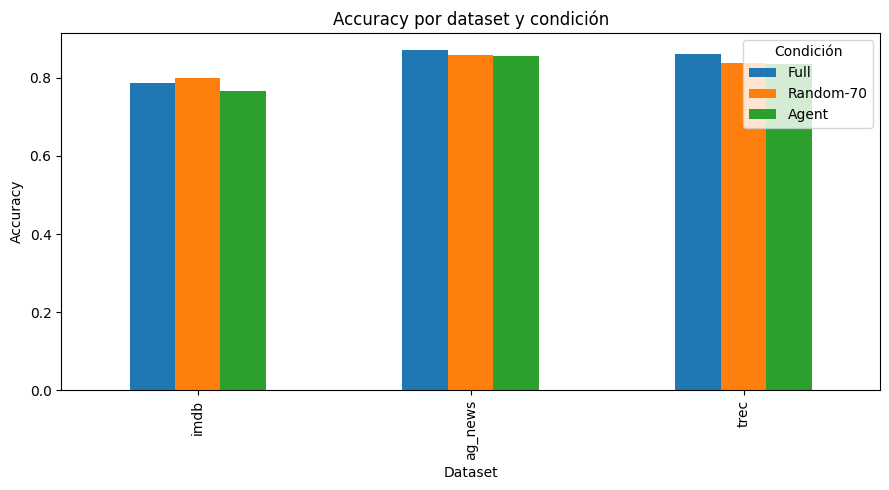

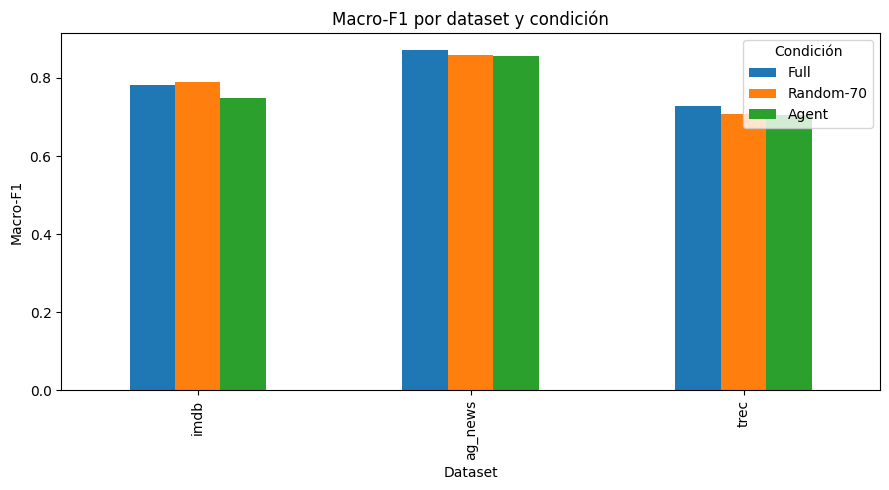

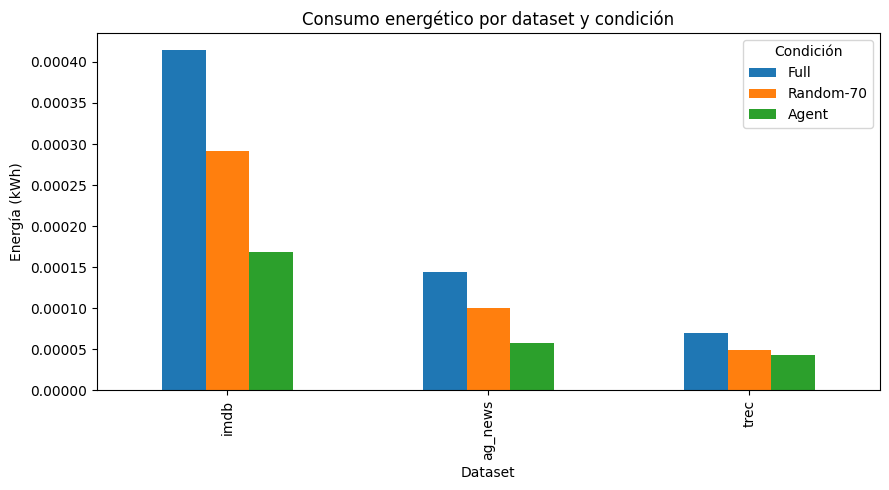

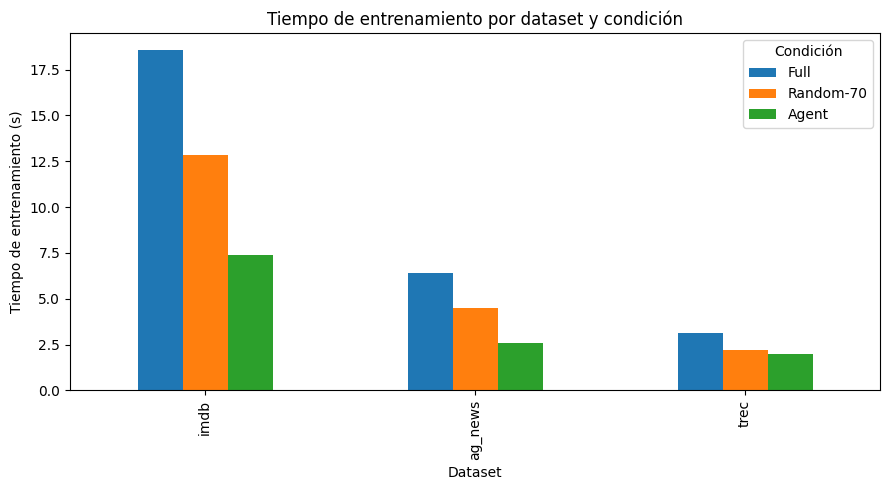

In [ ]:
import matplotlib.pyplot as plt

for metric, ylabel, filename, title in [
    ("accuracy", "Accuracy", "accuracy_final.png", "Accuracy por dataset y condición"),
    ("macro_f1", "Macro-F1", "macro_f1_final.png", "Macro-F1 por dataset y condición"),
    ("energy_kwh", "Energía (kWh)", "energy_final.png", "Consumo energético por dataset y condición"),
    ("training_time_s", "Tiempo de entrenamiento (s)", "time_final.png", "Tiempo de entrenamiento por dataset y condición"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    pivot = final_df.pivot_table(index="dataset", columns="condition", values=metric, aggfunc="mean").reindex(index=DATASETS, columns=CONDITIONS)
    pivot.plot(kind="bar", ax=ax)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Dataset")
    ax.set_title(title)
    ax.legend(title="Condición")
    fig.tight_layout()
    fig.savefig(EVAL_ROOT / filename, dpi=160)
    plt.show()
    plt.close(fig)

## 13. Manifiesto final y criterios de cierre

Se deja un manifiesto con hashes, entorno, GPU, política congelada, número de corridas y protocolo. La carpeta `final_evaluation_v2` constituye el bloque oficial de resultados de esta fase.


In [ ]:
manifest = {
    "experiment_name": EXPERIMENT_NAME,
    "saved_utc": datetime.utcnow().isoformat() + "Z",
    "datasets": DATASETS,
    "conditions": CONDITIONS,
    "evaluation_seeds": EVAL_SEEDS,
    "n_final_runs": int(len(history_df)),
    "target_model": TARGET_MODEL_NAME,
    "n_train_nominal": N_TRAIN,
    "n_validation_nominal": N_VAL,
    "test_policy": "official_test_preserved_exact_text_decontamination",
    "decontamination": {
        "method": "exact_text_sha256",
        "protected_split": "test",
        "filtered_splits": ["train", "validation"],
        "train_validation_checked_after_filtering": True,
        "train_after_by_dataset": {d: int(len(split_tables[d]["train"])) for d in DATASETS},
        "validation_after_by_dataset": {d: int(len(split_tables[d]["validation"])) for d in DATASETS},
        "test_size_by_dataset": {d: int(len(split_tables[d]["test"])) for d in DATASETS},
        "pdu_denominator": N_TRAIN,
        "pdu_definition": "n_selected / nominal_train_size_before_decontamination",
    },
    "max_token_cap": MAX_TOKEN_CAP,
    "min_token_cap": MIN_TOKEN_CAP,
    "batch_size": BATCH_SIZE,
    "train_epochs": TRAIN_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "codecarbon_measure_power_secs": CODECARBON_MEASURE_POWER_SECS,
    "ppo_experiment_signature": ppo_manifest["experiment_signature"],
    "ppo_model_sha256": model_hash,
    "ppo_reproducibility_manifest": ppo_repro,
    "environment_versions": VERSIONS,
    "gpu_name": GPU_NAME,
    "history_sha256": sha256_file(EVAL_HISTORY_PATH),
}
with open(EVAL_ROOT / "final_evaluation_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False, default=str)

full_ok = all(
    history_df.query("dataset == @d and condition == 'Full'")["n_selected"].eq(len(feature_tables[d])).all()
    for d in DATASETS
)
random_ok = all(
    history_df.query("dataset == @d and condition == 'Random-70'")["n_selected"].eq(int(math.ceil(0.70 * len(feature_tables[d])))).all()
    for d in DATASETS
)
text_disjoint_ok = all(
    text_hash_series(split_tables[d]["train"]).isdisjoint(text_hash_series(split_tables[d]["validation"]))
    and text_hash_series(split_tables[d]["train"]).isdisjoint(text_hash_series(split_tables[d]["test"]))
    and text_hash_series(split_tables[d]["validation"]).isdisjoint(text_hash_series(split_tables[d]["test"]))
    for d in DATASETS
)

closure = pd.DataFrame([
    {"control": "45 ejecuciones", "resultado": len(history_df) == 45},
    {"control": "15 por dataset", "resultado": all((history_df.dataset == d).sum() == 15 for d in DATASETS)},
    {"control": "5 semillas por condición", "resultado": all(history_df.groupby(["dataset", "condition"])["seed"].nunique() == 5)},
    {"control": "Full usa todo el Train descontaminado", "resultado": full_ok},
    {"control": "Random-70 usa ceil(0.70 × Train descontaminado)", "resultado": random_ok},
    {"control": "Train/Validation/Test textualmente disjuntos", "resultado": text_disjoint_ok},
    {"control": "Energía positiva", "resultado": bool((history_df["energy_kwh"] > 0).all())},
    {"control": "Test no participa en PPO", "resultado": True},
    {"control": "Política PPO congelada", "resultado": True},
])
closure.to_csv(EVAL_ROOT / "final_closure_checks.csv", index=False)
display(closure)

print("Evaluación final cerrada en:", EVAL_ROOT)
print("Historial:", EVAL_HISTORY_PATH)
print("Resumen:", EVAL_ROOT / "final_summary_by_dataset_condition.csv")
print("Descontaminación:", EVAL_ROOT / "decontamination_report.csv")
print("Manifiesto:", EVAL_ROOT / "final_evaluation_manifest.json")


,control,resultado
0,45 ejecuciones,True
1,15 por dataset,True
2,5 semillas por condición,True
3,Full usa todo el Train descontaminado,True
4,Random-70 usa ceil(0.70 × Train descontaminado),True
5,Train/Validation/Test textualmente disjuntos,True
6,Energía positiva,True
7,Test no participa en PPO,True
8,Política PPO congelada,True


Evaluación final cerrada en: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2
Historial: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2/final_evaluation_history.csv
Resumen: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2/final_summary_by_dataset_condition.csv
Descontaminación: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2/decontamination_report.csv
Manifiesto: /content/drive/MyDrive/idsf-eft/framework/final_evaluation_v2/final_evaluation_manifest.json
